# Analytics

This notebook perfoms a variety of visualizations on the epidemic engine data. While the dashboard implementations use hourly-bucketed data and focus on tracking trends, this notebook focuses more on all-time and metadata analyses.

### Load Data

In [ ]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from app.db import get_connection


def query_view(view_name: str) -> pd.DataFrame:
    """Query a named database view and return the results as a DataFrame."""
    with get_connection() as conn:
        return pd.read_sql_query(f"SELECT * FROM public.{view_name}", conn)

In [ ]:
# Load raw data views into dataframes

df_clinic_visit = query_view("vw_clinic_visit_raw")
df_hospital_admission = query_view("vw_hospital_admission_raw")
df_symptom_report = query_view("vw_symptom_report_raw")
df_vaccination_record = query_view("vw_vaccination_record_raw")

view_data = [
    (df_clinic_visit, "Clinic Visit"),
    (df_hospital_admission, "Hospital Admission"),
    (df_symptom_report, "Symptom Report"),
    (df_vaccination_record, "Vaccination Record"),
]

C:\Users\eferg\AppData\Local\Temp\ipykernel_8376\4203630837.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(f"SELECT * FROM public.{view_name}", conn)
C:\Users\eferg\AppData\Local\Temp\ipykernel_8376\4203630837.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(f"SELECT * FROM public.{view_name}", conn)
C:\Users\eferg\AppData\Local\Temp\ipykernel_8376\4203630837.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql_query(f"SELECT * FROM public.{view_nam

## Timestamp Analysis

### Ingestion Delay
We noticed that there is not always a consistent delta between when an event occurs, and when it appears in Kafka. How long should we expect to wait until we can consider data "complete"?

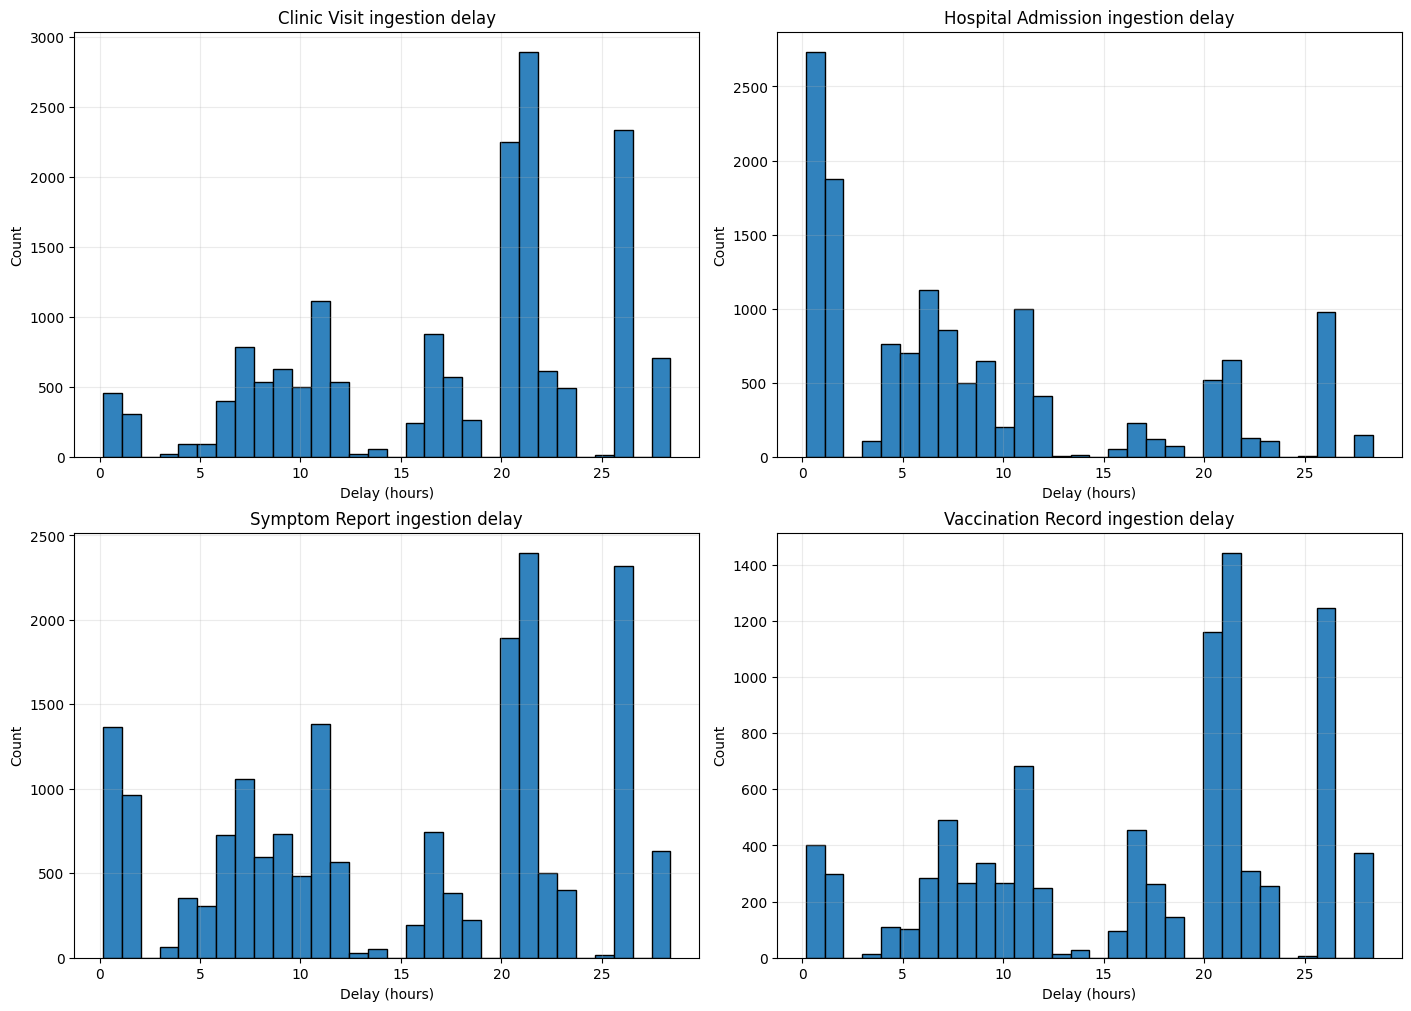

In [ ]:
df_clinic_visit['ingestion-delay'] = df_clinic_visit['ingested_at']-df_clinic_visit['event_ts']
df_hospital_admission['ingestion-delay'] = df_hospital_admission['ingested_at']-df_hospital_admission['event_ts']
df_symptom_report['ingestion-delay'] = df_symptom_report['ingested_at']-df_symptom_report['event_ts']
df_vaccination_record['ingestion-delay'] = df_vaccination_record['ingested_at']-df_vaccination_record['event_ts']

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
axes = axes.flatten()

for ax, (df, title) in zip(axes, view_data):
    df = df.copy()
    data = (df['ingestion-delay']/pd.Timedelta(hours=1)).dropna()

    ax.hist(data, bins=30, color="#3182bd", edgecolor="black")
    ax.set_title(f"{title} Ingestion Delay")
    ax.set_xlabel("Delay (hours)")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.25)

plt.show()

Most records come in between the 20-26 hour mark, except for hospital admissions, which are more likely to have a delay of <2 hours.

### Ingestion Timing
When are records more likely to appear in Kafka? Are there times of day we should be prepared to schedule extra resources?

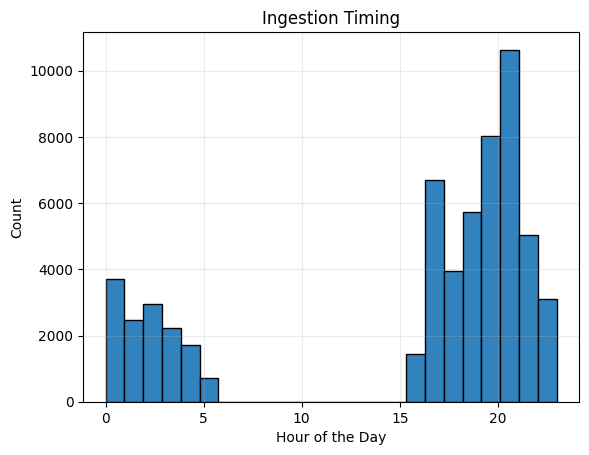

In [55]:
ax = plt.gca()

ax.hist(pd.concat([df_clinic_visit['ingested_at'].dt.hour,
                   df_hospital_admission['ingested_at'].dt.hour,
                   df_symptom_report['ingested_at'].dt.hour,
                   df_vaccination_record['ingested_at'].dt.hour]),
                   bins=24, color="#3182bd", edgecolor="black")

ax.set_title(f"Ingestion Timing")
ax.set_xlabel("Hour of the Day")
ax.set_ylabel("Count")
ax.grid(alpha=0.25)

plt.show()

Ingestion times are heavily concentrated around 8pm. This might be reflective of when we have been running the pipeline: we'd have to see if this data changed after running the pipeline continuously for a day plus.

### Patient Arrival by Severity
Several of these health events are within an organization's control and can be planned around (e.g. vaccinations, routine checkups). To help clinics and hospitals with their planning, are there times of day that severe, unscheduled events are more likely to occur?

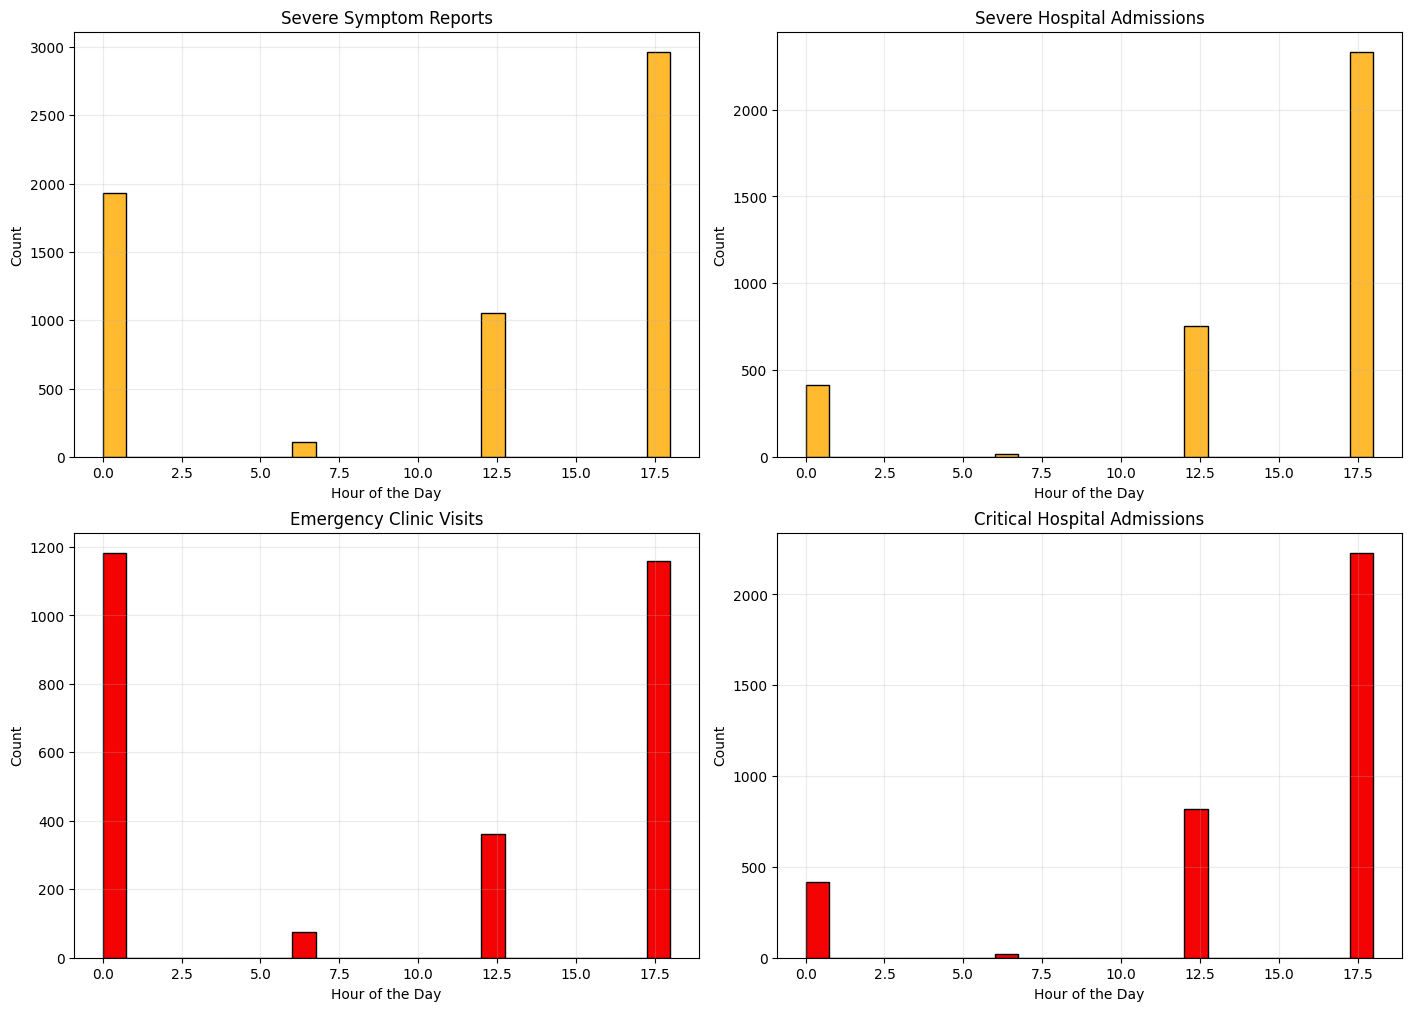

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

axes[0,0].hist(df_symptom_report['event_ts'][df_symptom_report['severity']=='severe'].dt.hour.dropna(),
               bins=24, color="#ffba2f", edgecolor="black")
axes[0,0].set_title("Severe Symptom Reports")

axes[1,0].hist(df_clinic_visit['event_ts'][df_clinic_visit['visit_type']=='emergency'].dt.hour.dropna(),
               bins=24, color="#f30303", edgecolor="black")
axes[1,0].set_title("Emergency Clinic Visits")

axes[0,1].hist(df_hospital_admission['event_ts'][df_hospital_admission['severity']=='severe'].dt.hour.dropna(),
               bins=24, color="#ffba2f", edgecolor="black")
axes[0,1].set_title("Severe Hospital Admissions")

axes[1,1].hist(df_hospital_admission['event_ts'][df_hospital_admission['severity']=='critical'].dt.hour.dropna(),
               bins=24, color="#f30303", edgecolor="black")
axes[1,1].set_title("Critical Hospital Admissions")

axes = axes.flatten()

for ax in axes:
    ax.set_xlabel("Hour of the Day")
    ax.set_ylabel("Count")
    ax.grid(alpha=0.25)

plt.show()

Almost all severe or critical events happen at midnight or 5:30. Curious. This should definitely be investigated further to see if it's an anomaly of the data.

## Location, Location, Location

### Region Distribution
How is our data distributed by region and clinic? Are any locations over/under-represented?

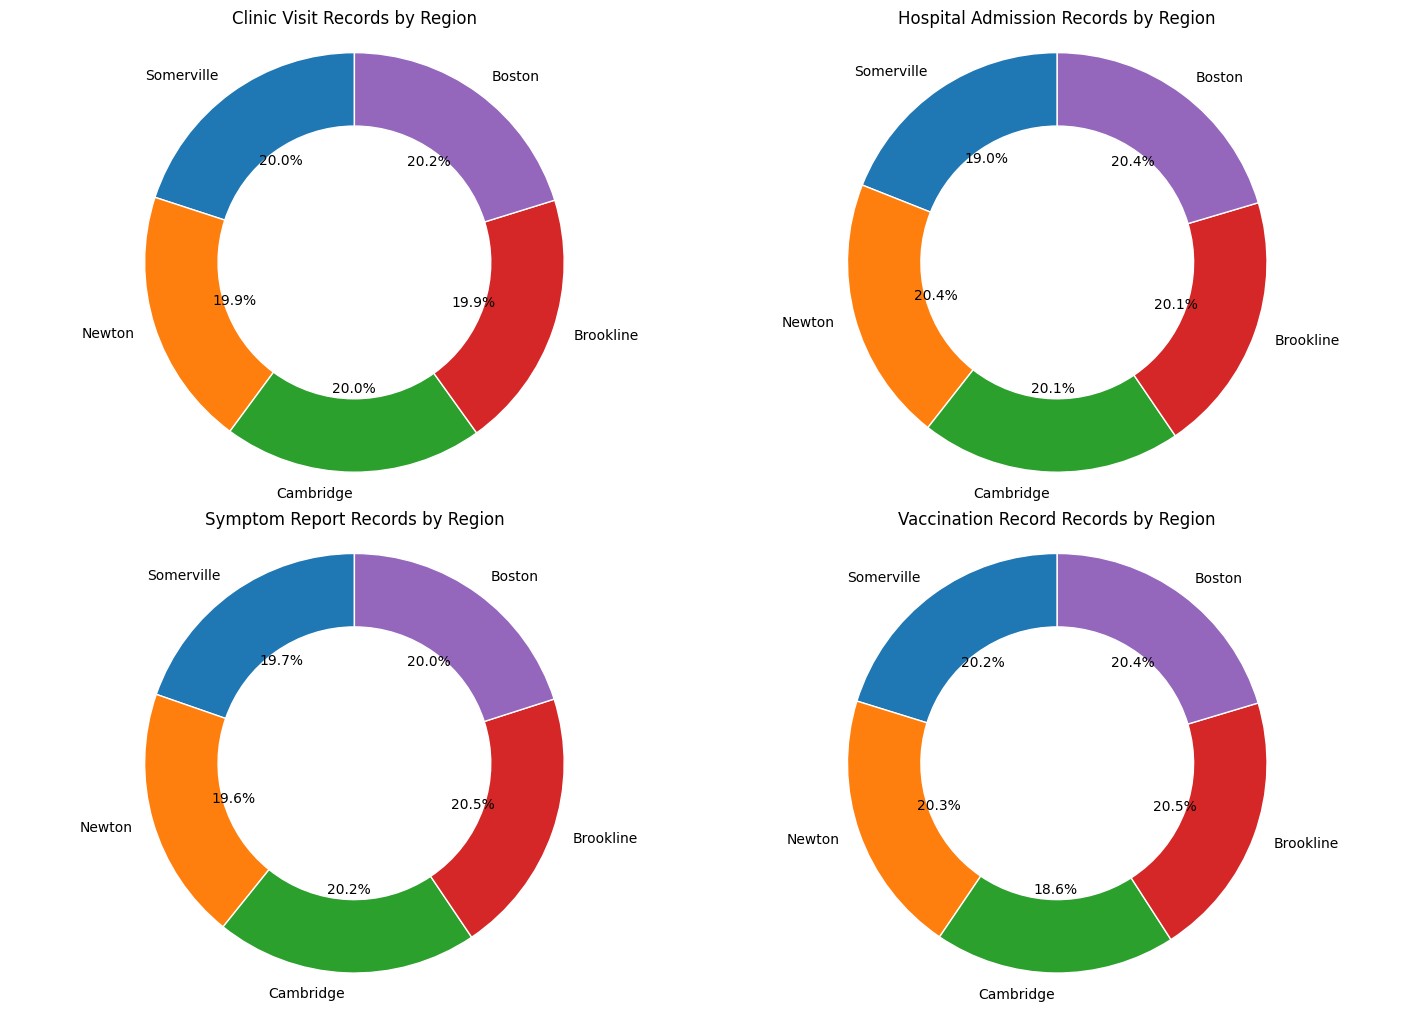

In [80]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
axes = axes.flatten()

for ax, (df, title) in zip(axes, view_data):
    df = df.copy()
    data = df["region"].fillna("Unknown").value_counts().sort_index(ascending=False)

    ax.pie(
        data,
        labels=data.index,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops=dict(width=0.35, edgecolor="white"),
        )
    ax.set_title(f"{title} Records by Region")
    ax.axis("equal")

plt.show()

Nope! Totally evenly distributed. What about by hospital and clinic id?

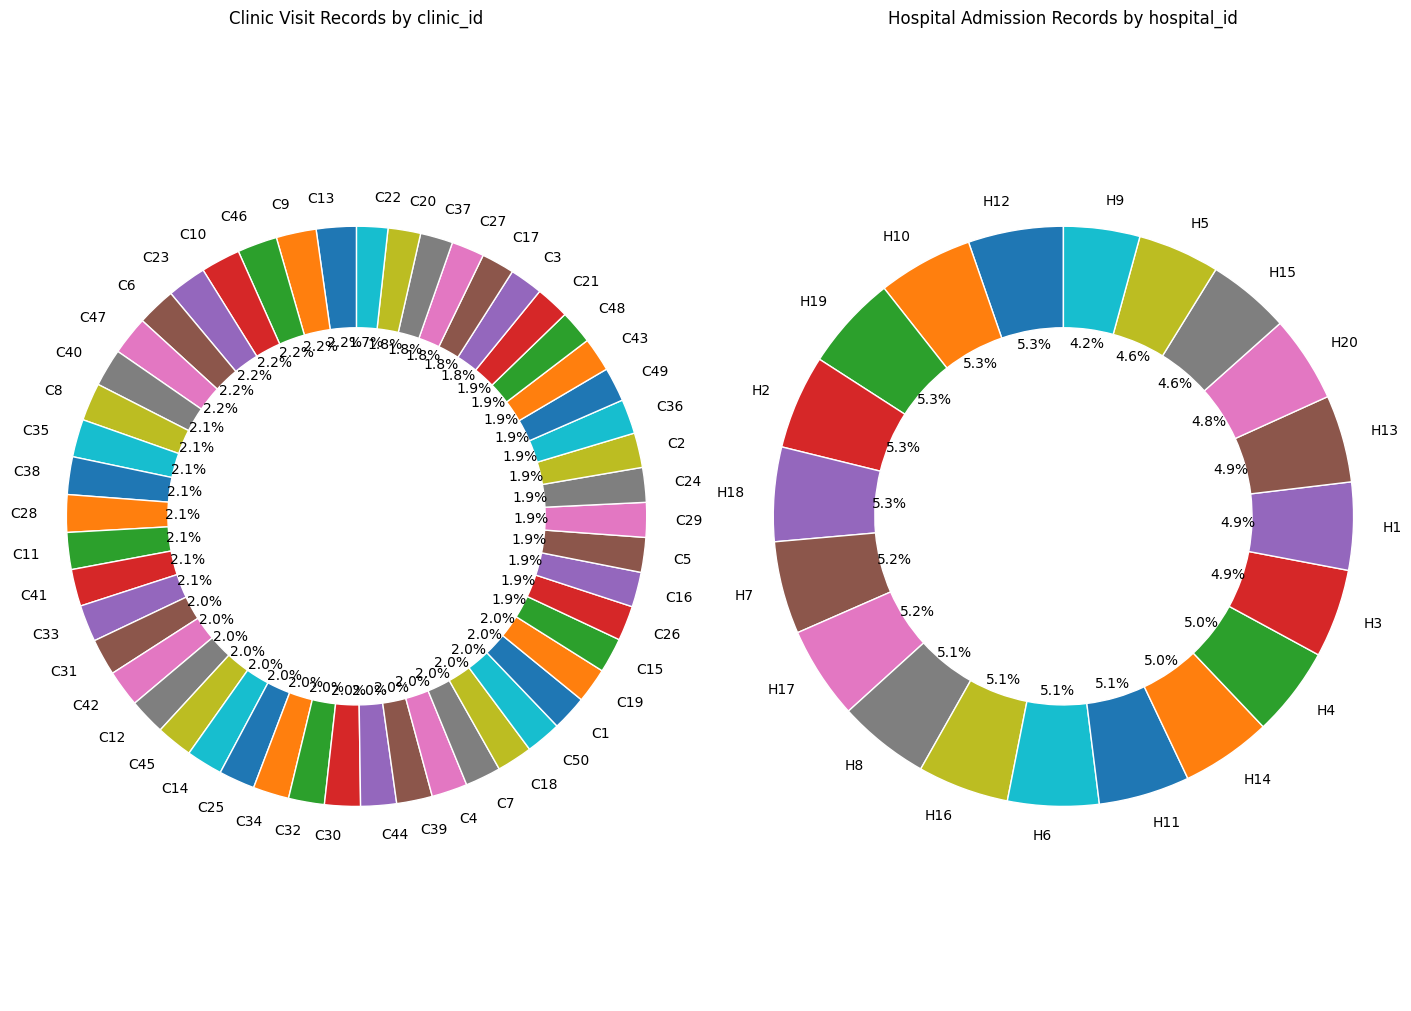

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 10), constrained_layout=True)

data = df_clinic_visit["clinic_id"].fillna("Unknown").value_counts().sort_values(ascending=False)
axes[0].pie(
        data,
        labels=data.index,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops=dict(width=0.35, edgecolor="white"),
        )
axes[0].set_title(f"Clinic Visit Records by clinic_id")
axes[0].axis("equal")

data = df_hospital_admission["hospital_id"].fillna("Unknown").value_counts().sort_values(ascending=False)
axes[1].pie(
        data,
        labels=data.index,
        autopct="%1.1f%%",
        startangle=90,
        wedgeprops=dict(width=0.35, edgecolor="white"),
        )
axes[1].set_title(f"Hospital Admission Records by hospital_id")
axes[1].axis("equal")


plt.show()

## Correlation
Are any particular data points associated with better/worse health outcomes? Could be useful for triage, or public awareness campaigns.

### Hospital - Predicting LoS
First, let's look at severity and admission_reason, and see if either predicts how long someone might be in the hospital.

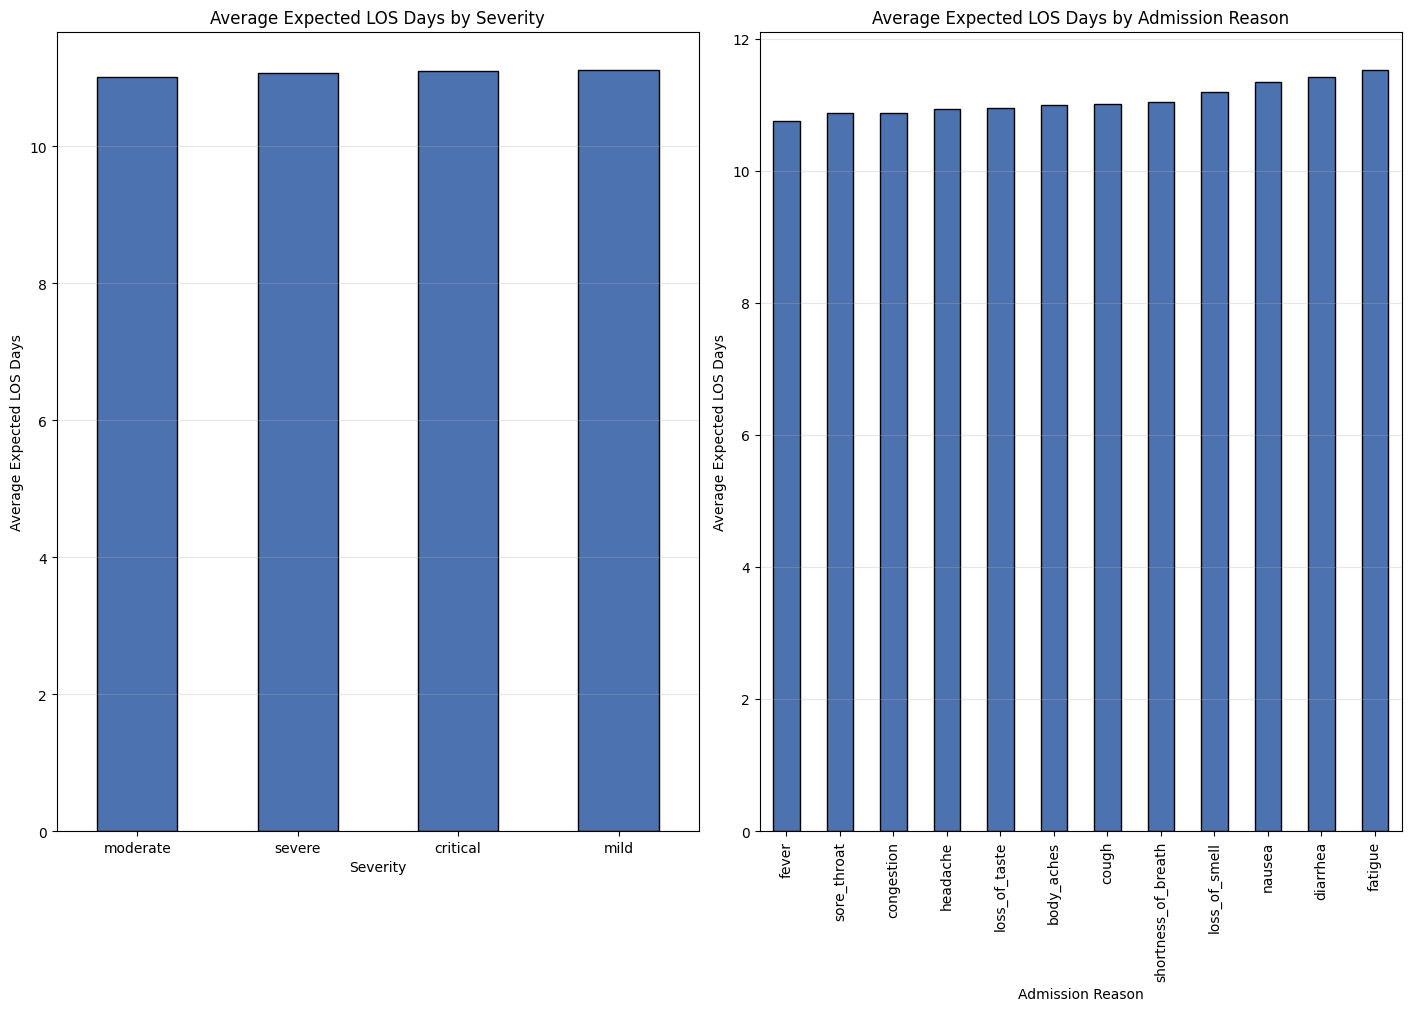

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 10), constrained_layout=True)

los_by_severity = (
    df_hospital_admission.groupby("severity")["expected_los_days"]
    .mean()
    .sort_values()
)

los_by_severity.plot(
    kind="bar",
    color="#4c72b0",
    edgecolor="black",
    ax=axes[0],
)
axes[0].set_title("Average Expected LoS Days by Severity")
axes[0].set_xlabel("Severity")
axes[0].set_ylabel("Average Expected LoS Days")
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)

los_by_admission_reason = (
    df_hospital_admission.groupby("admission_reason")["expected_los_days"]
    .mean()
    .sort_values()
)

los_by_admission_reason.plot(
    kind="bar",
    color="#4c72b0",
    edgecolor="black",
    ax=axes[1],
)
axes[1].set_title("Average Expected LoS Days by Admission Reason")
axes[1].set_xlabel("Admission Reason")
axes[1].set_ylabel("Average Expected LoS Days")
axes[1].grid(axis="y", alpha=0.3)
#axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)

plt.show()

No difference. Let's look at temperature and oxygen anomalies, and use a scatterplot this time.

Text(0, 0.5, 'LoS Days')

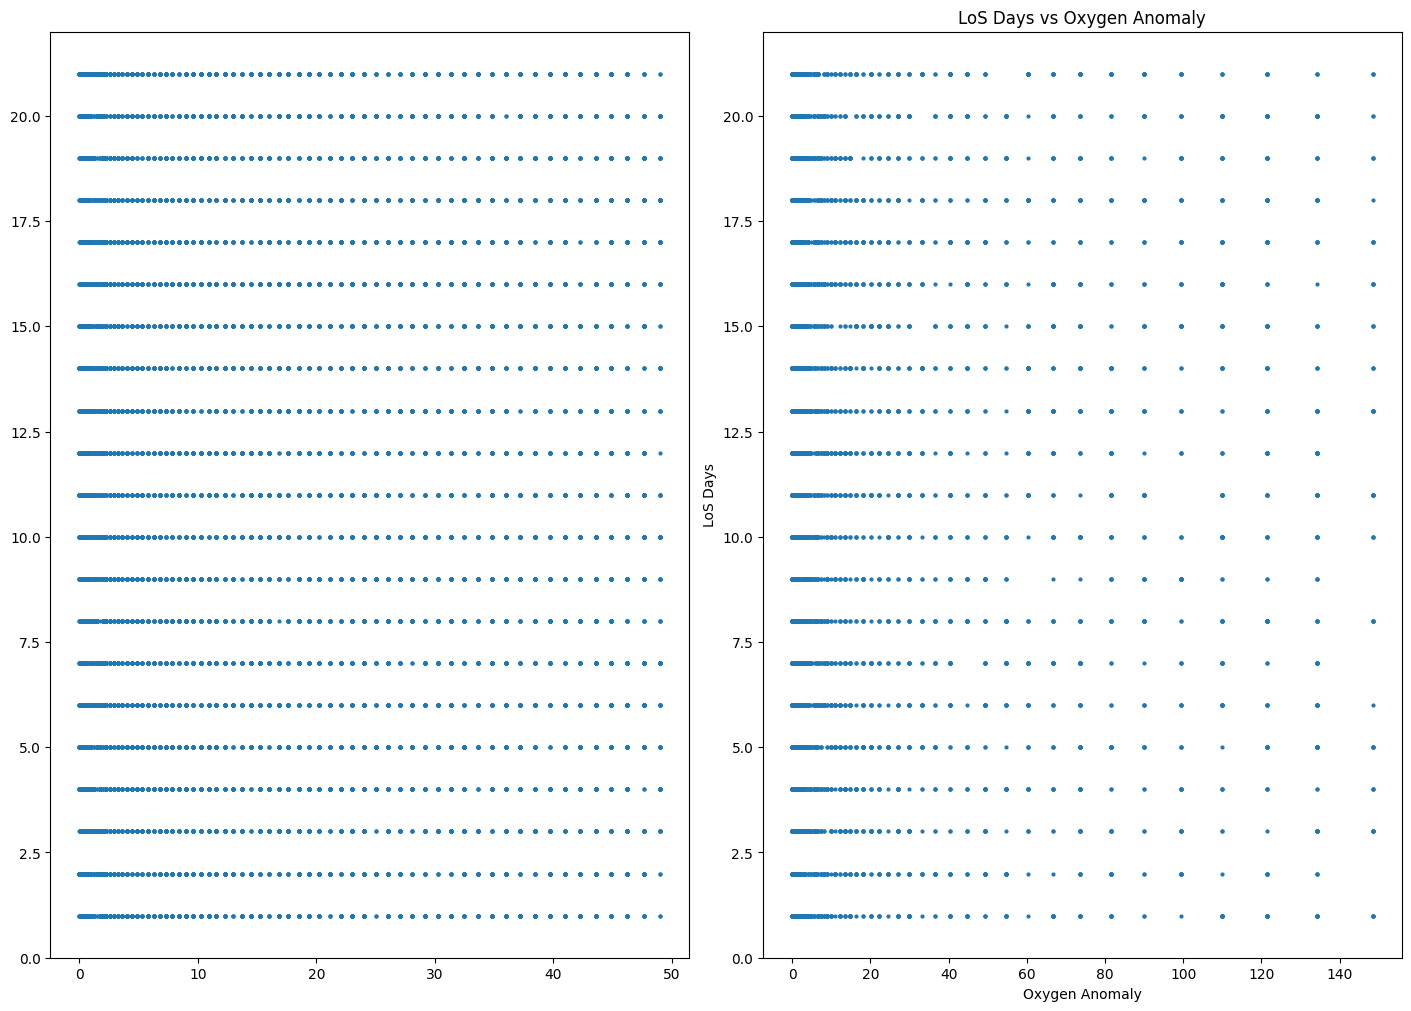

In [ ]:
# rough approximation of severity of conditions
df_hospital_admission['oxygen_anomaly'] = np.exp(90-df_hospital_admission['oxygen_level'])
df_hospital_admission['temp_anomaly'] = (df_hospital_admission['temperature_f']-98)**2

fig, axes = plt.subplots(1, 2, figsize=(14, 10), constrained_layout=True)

axes[0].scatter(df_hospital_admission['temp_anomaly'],
                df_hospital_admission['expected_los_days'],
                s=4)

axes[1].set_title("LoS Days vs Temperature Anomaly")
axes[1].set_xlabel("Temperature Anomaly")
axes[1].set_ylabel("LoS Days")


axes[1].scatter(df_hospital_admission['oxygen_anomaly'],
                df_hospital_admission['expected_los_days'],
                s=4)

axes[1].set_title("LoS Days vs Oxygen Anomaly")
axes[1].set_xlabel("Oxygen Anomaly")
axes[1].set_ylabel("LoS Days")

Once again, perfectly distributed.